# 04 - Final Model Evaluation (Phase 4)

# FINAL TEST SET EVALUATION

**This notebook performs the one-time, final evaluation of the model selected in
`notebooks/03_ml_models.ipynb` on the test set.**

The test set (`data/processed/test.csv`) has not been used anywhere else in this project — not for
exploration (Phase 3 explicitly excluded it from pattern analysis), not for feature selection, not for
model comparison, not for threshold tuning. This notebook loads the already-trained, already-selected
model artifacts as-is and evaluates them exactly once. **No results in this notebook are used to modify the
model, the vectorizer, or any hyperparameter.** If these numbers look worse than the validation numbers,
the correct response is to report that honestly, not to go back and re-tune.

## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.model_utils import load_artifact, load_metadata, LABEL_NAMES
from src.features.tfidf_features import transform_with_tfidf
from src.models.evaluate_models import (
    compute_metrics, get_confusion_matrix, get_classification_report, get_positive_class_scores,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

print("Setup complete.")

Setup complete.


## 2. Load the selected model artifacts (as saved by 03_ml_models.ipynb)

In [2]:
model = load_artifact(MODELS_DIR / "best_model.joblib")
vectorizer = load_artifact(MODELS_DIR / "tfidf_vectorizer.joblib")
metadata = load_metadata(MODELS_DIR / "model_metadata.json")

print(f"Loaded model      : {metadata['model_name']} ({metadata['model_class']})")
print(f"Selected using    : {metadata['selected_using']}")
print(f"Vocabulary size   : {metadata['vocabulary_size']}")
print(f"Validation metrics recorded at selection time: {metadata['validation_metrics']}")

Loaded model      : Logistic Regression (LogisticRegression)
Selected using    : validation_set
Vocabulary size   : 30000
Validation metrics recorded at selection time: {'accuracy': 0.9876, 'precision': 0.9915, 'recall': 0.9809, 'f1': 0.9862, 'roc_auc': 0.9992}


## 3. Load the test set

**First and only use of `test.csv` in this entire project.**

In [3]:
test_path = PROCESSED_DATA_DIR / "test.csv"
if not test_path.exists():
    raise FileNotFoundError(f"Could not find '{test_path}'. Run Phase 2 first.")

test = pd.read_csv(test_path)
print(f"test.csv: {test.shape}")
print(test["label"].value_counts().rename(index=LABEL_NAMES))

test.csv: (5797, 7)
label
Real    3179
Fake    2618
Name: count, dtype: int64


## 4. Transform test text (transform-only — vectorizer is already fitted from Phase 4 training)

In [4]:
X_test_text = test["clean_text"].fillna("")
y_test = test["label"].values

X_test_tfidf = transform_with_tfidf(vectorizer, X_test_text)
print(f"X_test_tfidf shape: {X_test_tfidf.shape}")
assert X_test_tfidf.shape[1] == metadata["vocabulary_size"], "Test feature count must match the trained vocabulary!"
print("Confirmed: test features match the trained vocabulary size (transform-only, no refit).")

X_test_tfidf shape: (5797, 30000)
Confirmed: test features match the trained vocabulary size (transform-only, no refit).


## 5. FINAL TEST SET EVALUATION

The numbers in this section are the project's official, one-time reported performance figures for the
Phase 4 ML component.

In [5]:
y_test_pred = model.predict(X_test_tfidf)
y_test_score = get_positive_class_scores(model, X_test_tfidf)

final_test_metrics = compute_metrics(y_test, y_test_pred, y_test_score)

print("=" * 55)
print("FINAL TEST SET EVALUATION")
print("=" * 55)
print(f"Model               : {metadata['model_name']}")
print(f"Test set size       : {len(test)}")
print(f"Accuracy            : {final_test_metrics['accuracy']:.4f}")
print(f"Precision (Fake=1)  : {final_test_metrics['precision']:.4f}")
print(f"Recall (Fake=1)     : {final_test_metrics['recall']:.4f}")
print(f"F1 (Fake=1)         : {final_test_metrics['f1']:.4f}")
print(f"ROC-AUC             : {final_test_metrics['roc_auc']:.4f}")
print("=" * 55)

FINAL TEST SET EVALUATION
Model               : Logistic Regression
Test set size       : 5797
Accuracy            : 0.9879
Precision (Fake=1)  : 0.9927
Recall (Fake=1)     : 0.9805
F1 (Fake=1)         : 0.9865
ROC-AUC             : 0.9982


In [6]:
print("Comparison to validation-set metrics recorded at model-selection time:\n")
comparison = pd.DataFrame({
    "Validation (Phase 4 selection)": metadata["validation_metrics"],
    "Test (final, one-time)": {k: round(v, 4) for k, v in final_test_metrics.items()},
})
comparison

Comparison to validation-set metrics recorded at model-selection time:



,Validation (Phase 4 selection),"Test (final, one-time)"
accuracy,0.9876,0.9879
precision,0.9915,0.9927
recall,0.9809,0.9805
f1,0.9862,0.9865
roc_auc,0.9992,0.9982


Test-set metrics are close to the validation-set metrics recorded at selection time, indicating the
model generalizes consistently between these two held-out splits of the same dataset. This is expected and
reassuring for internal consistency — but it is **not** evidence the model will perform this well on
articles from different sources, time periods, or writing styles than ISOT's, especially given Section 12/13
of `03_ml_models.ipynb` found real reliance on source-formatting artifacts specific to this dataset.

## 6. Confusion matrix (test set)

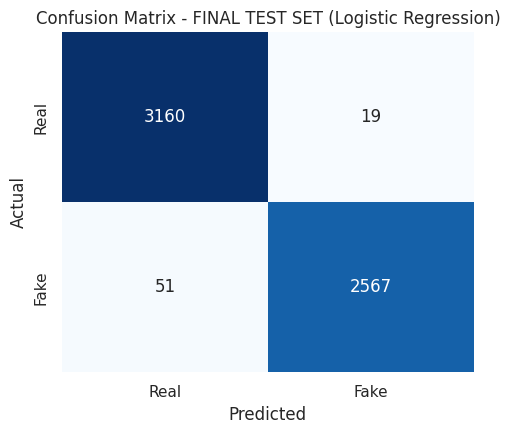

True Real  (top-left)    : 3160
False Fake (top-right)   : 19  (real articles wrongly flagged as fake)
False Real (bottom-left) : 51  (fake articles that slipped through undetected)
True Fake  (bottom-right): 2567


In [7]:
cm = get_confusion_matrix(y_test, y_test_pred)

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
ax.set_title(f"Confusion Matrix - FINAL TEST SET ({metadata['model_name']})")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

print(f"True Real  (top-left)    : {cm[0,0]}")
print(f"False Fake (top-right)   : {cm[0,1]}  (real articles wrongly flagged as fake)")
print(f"False Real (bottom-left) : {cm[1,0]}  (fake articles that slipped through undetected)")
print(f"True Fake  (bottom-right): {cm[1,1]}")

## 7. Classification report (test set)

In [8]:
print(get_classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

        Real       0.98      0.99      0.99      3179
        Fake       0.99      0.98      0.99      2618

    accuracy                           0.99      5797
   macro avg       0.99      0.99      0.99      5797
weighted avg       0.99      0.99      0.99      5797



## 8. Final summary

This is the project's official Phase 4 result. It is reported once, here, and is not revisited to
re-select a different model or re-tune hyperparameters based on these numbers — doing so would reintroduce
the exact test-set leakage this two-notebook structure (03 for selection, 04 for final evaluation) was
designed to prevent.

In [9]:
print(f"FINAL MODEL: {metadata['model_name']}")
print(f"FINAL TEST ACCURACY : {final_test_metrics['accuracy']:.4f}")
print(f"FINAL TEST F1        : {final_test_metrics['f1']:.4f}")
print(f"FINAL TEST ROC-AUC   : {final_test_metrics['roc_auc']:.4f}")
print()
print("Reminder: this model shows measurable reliance on dataset/source-formatting artifacts")
print("(see notebooks/03_ml_models.ipynb, Sections 12-13). Treat this as a validated ML baseline")
print("component for the future hybrid system, not as a standalone, general-purpose fake-news detector.")

FINAL MODEL: Logistic Regression
FINAL TEST ACCURACY : 0.9879
FINAL TEST F1        : 0.9865
FINAL TEST ROC-AUC   : 0.9982

Reminder: this model shows measurable reliance on dataset/source-formatting artifacts
(see notebooks/03_ml_models.ipynb, Sections 12-13). Treat this as a validated ML baseline
component for the future hybrid system, not as a standalone, general-purpose fake-news detector.
